# Chapter 19: Why Circles Keep Saying Pi

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will see why circumference divided by diameter is the same number for every circle, recover a radius from a circumference before finding an area, watch circumference and area respond differently when a radius doubles, and measure an angle by the arc it reaches.

**A note before you start:** the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight down the page like a short chapter. If you are curious, peek at the code, and change a number to see what happens.

## Setup

This cell loads the tools for the calculations and the pictures. Nothing to change here.

In [1]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, Wedge

INK, TEAL, TERRA, GREY, LIGHT = "#172a3b", "#2f7f79", "#a24a33", "#6b7785", "#d5dbe1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def say(label, text):
    """Print one labeled line of a worked calculation."""
    print(f"{label}: {text}")
from fractions import Fraction

## 1. The ratio that never changes

**Question:** why does circumference divided by diameter give the same number for a small circle and a large one?

**The equations from the chapter:**

$$\pi = \frac{C}{d} \qquad\qquad C = \pi d$$

**What the symbols mean:** $C$ is the circumference, the length once around the boundary. $d$ is the diameter, a straight segment through the center from one side to the other. $\pi$ is the number of diameters that fit around the edge, about 3.14159.

**Predict first:** the tabletop has diameter 1.2 m. Will a circle with diameter 4 m give a different ratio?

In [2]:
d = 1.2
say("Diameter d", f"{d} m")
say("Circumference C (exact)", f"{d}\u03c0 m")
say("Circumference C (nearest hundredth)", f"{math.pi * d:.2f} m")
say("C / d", f"{d}\u03c0 m / {d} m = \u03c0 (no unit)")
say("Pencil check", f"3.14159 x {d} = {3.14159 * d:.2f} to the nearest hundredth")
print()
print("Other menu values:")
for dd in [2, 4]:
    print(f"  d = {dd} m: C = \u03c0 x {dd} = {dd}\u03c0 = {math.pi*dd:.2f} m, and C / d = {dd}\u03c0 / {dd} = \u03c0")
print()
print("The chord slip: a segment that misses the center (0.8 of the diameter):")
for dd in ["1.2", "2", "4"]:
    x = float(dd); ch = 0.8 * x
    print(f"  d = {dd} m: chord = 0.8 x {dd} = {ch:g} m, C / chord = {math.pi*x:.2f} / {ch:g} = {math.pi*x/ch:.2f}, not \u03c0")

Diameter d: 1.2 m
Circumference C (exact): 1.2π m
Circumference C (nearest hundredth): 3.77 m
C / d: 1.2π m / 1.2 m = π (no unit)
Pencil check: 3.14159 x 1.2 = 3.77 to the nearest hundredth

Other menu values:
  d = 2 m: C = π x 2 = 2π = 6.28 m, and C / d = 2π / 2 = π
  d = 4 m: C = π x 4 = 4π = 12.57 m, and C / d = 4π / 4 = π

The chord slip: a segment that misses the center (0.8 of the diameter):
  d = 1.2 m: chord = 0.8 x 1.2 = 0.96 m, C / chord = 3.77 / 0.96 = 3.93, not π
  d = 2 m: chord = 0.8 x 2 = 1.6 m, C / chord = 6.28 / 1.6 = 3.93, not π
  d = 4 m: chord = 0.8 x 4 = 3.2 m, C / chord = 12.57 / 3.2 = 3.93, not π


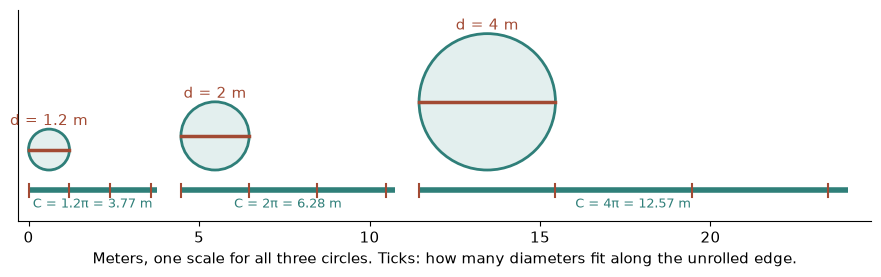

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x0 = 0.0
for dd in [1.2, 2, 4]:
    r = dd / 2
    ax.add_patch(Circle((x0 + r, r), r, facecolor="#e3efee", edgecolor=TEAL, linewidth=2))
    ax.plot([x0, x0 + dd], [r, r], color=TERRA, linewidth=2.5)
    ax.text(x0 + r, dd + 0.12, f"d = {dd} m", ha="center", color=TERRA)
    # the unrolled edge, below the circle
    C = math.pi * dd
    ax.plot([x0, x0 + C], [-0.6, -0.6], color=TEAL, linewidth=4, solid_capstyle="butt")
    for k in range(int(C // dd) + 1):
        ax.plot([x0 + k * dd] * 2, [-0.8, -0.4], color=TERRA, linewidth=1.5)
    ax.text(x0 + C / 2, -1.1, f"C = {dd}\u03c0 = {C:.2f} m", ha="center", fontsize=9, color=TEAL)
    x0 += max(C, dd) + 0.7
ax.set_xlim(-0.3, x0); ax.set_ylim(-1.5, 4.7); ax.set_aspect("equal"); ax.set_yticks([])
ax.set_xlabel("Meters, one scale for all three circles. Ticks: how many diameters fit along the unrolled edge.")
plt.tight_layout(); plt.show()

**What this shows:** unroll each circle's edge and lay diameters along it. A little more than three always fit (that "little more" is the 0.14159...). The size changes; the ratio does not.

**Where it stops working:** the ratio belongs to the segment through the center. A chord that misses the center is not a diameter, and C divided by that chord (about 3.93 for the 0.8 chord) is not $\pi$.

## 2. Recover the radius first

**Question:** given only the circumference, how do you find the area without slipping a diameter into $\pi r^2$?

**The equations from the chapter:**

$$2\pi r=14\pi \qquad\qquad \pi(7)^2=49\pi$$

**What the symbols mean:** $r$ is the radius, from the center to the edge. $2\pi r$ is the circumference. $\pi r^2$ is the area, in square centimeters here.

**Predict first:** if you accidentally put the diameter 14 into $\pi r^2$ instead of the radius 7, how far off will the area be?

In [4]:
C = 14   # circumference is 14 pi cm
r = C / 2
d = 2 * r
say("Circumference", f"{C}\u03c0 cm")
say("Radius from 2\u03c0r = C", f"{C}\u03c0 / 2\u03c0 = {r:g} cm")
say("Diameter", f"{d:g} cm")
say("Area \u03c0 x (length used)\u00b2", f"\u03c0 x {r:g}\u00b2 = {r*r:g}\u03c0 cm\u00b2")
say("Correct area", f"{r*r:g}\u03c0 cm\u00b2")
say("Check", f"2\u03c0 x {r:g} = {2*r:g}\u03c0")
print()
print("The slip (diameter used as the radius):")
say("Area \u03c0 x (length used)\u00b2", f"\u03c0 x {d:g}\u00b2 = {d*d:g}\u03c0 cm\u00b2")
say("Ratio to the true area", f"{d*d:g} / {r*r:g} = {d*d/(r*r):g}, four times too big")
print()
print("Other menu values:")
for CC in [10, 6]:
    rr = CC / 2
    print(f"  circumference {CC}\u03c0: r = {CC}/2 = {rr:g}, area = \u03c0 x {rr:g}\u00b2 = {rr*rr:g}\u03c0 cm\u00b2; slip: \u03c0 x {CC}\u00b2 = {CC*CC}\u03c0")

Circumference: 14π cm
Radius from 2πr = C: 14π / 2π = 7 cm
Diameter: 14 cm
Area π x (length used)²: π x 7² = 49π cm²
Correct area: 49π cm²
Check: 2π x 7 = 14π

The slip (diameter used as the radius):
Area π x (length used)²: π x 14² = 196π cm²
Ratio to the true area: 196 / 49 = 4, four times too big

Other menu values:
  circumference 10π: r = 10/2 = 5, area = π x 5² = 25π cm²; slip: π x 10² = 100π
  circumference 6π: r = 6/2 = 3, area = π x 3² = 9π cm²; slip: π x 6² = 36π


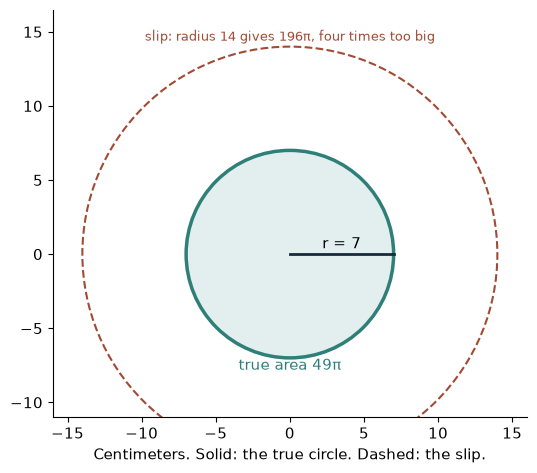

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(Circle((0, 0), d, fill=False, edgecolor=TERRA, linewidth=1.5, linestyle="dashed"))
ax.add_patch(Circle((0, 0), r, facecolor="#e3efee", edgecolor=TEAL, linewidth=2.5))
ax.plot([0, r], [0, 0], color=INK, linewidth=2)
ax.text(r / 2, 0.4, f"r = {r:g}", ha="center")
ax.text(0, -r - 0.8, f"true area {r*r:g}\u03c0", ha="center", color=TEAL)
ax.text(0, d + 0.4, f"slip: radius 14 gives {d*d:g}\u03c0, four times too big", ha="center", color=TERRA, fontsize=9)
ax.set_xlim(-16, 16); ax.set_ylim(-11, 16.5); ax.set_aspect("equal")
ax.set_xlabel("Centimeters. Solid: the true circle. Dashed: the slip.")
plt.tight_layout(); plt.show()

**What this shows:** the circumference gives the radius first ($2\pi r = 14\pi$ means $r = 7$), and only then do you square it. Putting the diameter where the radius belongs doubles the length, and squaring turns that doubling into a factor of 4 in the area.

**Where it stops working:** all of this describes an ideal circle with a stated radius or circumference. A real ring or wheel has thickness and wobble that the model ignores.

## 3. Double the radius

**Question:** when the tabletop's radius doubles, why does the area grow more than the circumference?

**The equation from the chapter:**

$$A = \pi r^2$$

**What the symbols mean:** $r$ is the radius in meters. The circumference $2\pi r$ is a length in meters. The area $\pi r^2$ is in square meters. The tabletop starts at radius $0.6$ m (diameter 1.2 m), so $C = 1.2\pi$ m and $A = 0.36\pi$ m².

**Predict first:** if the radius doubles, by what factor will the circumference grow, and by what factor the area?

In [6]:
r1 = Fraction(6, 10)
def scale(k):
    k = Fraction(k)
    r2 = k * r1
    c1, c2 = 2 * r1, 2 * r2
    a1, a2 = r1 * r1, r2 * r2
    g = lambda x: f"{float(x):g}"
    print(f"  New radius {g(k)} x {g(r1)} = {g(r2)} m.")
    print(f"  Circumference: 2\u03c0 x {g(r2)} = {g(c2)}\u03c0 m, which is {g(k)} times {g(c1)}\u03c0")
    print(f"  Area: \u03c0 x {g(r2)}\u00b2 = {g(a2)}\u03c0 m\u00b2, which is {g(k)}\u00b2 = {g(k*k)} times {g(a1)}\u03c0")
    print(f"  Lengths take one factor of {g(k)}; area takes two.")
    print(f"  Summary: circumference {g(c1)}\u03c0 m to {g(c2)}\u03c0 m (x {g(c2/c1)}); area {g(a1)}\u03c0 m\u00b2 to {g(a2)}\u03c0 m\u00b2 (x {g(a2/a1)})")

print("Default: scale factor 2")
scale(2)
print()
print("Other menu values:")
for k in ["1/2", "1", "3"]:
    print(f"scale factor {k}:")
    scale(k)

Default: scale factor 2
  New radius 2 x 0.6 = 1.2 m.
  Circumference: 2π x 1.2 = 2.4π m, which is 2 times 1.2π
  Area: π x 1.2² = 1.44π m², which is 2² = 4 times 0.36π
  Lengths take one factor of 2; area takes two.
  Summary: circumference 1.2π m to 2.4π m (x 2); area 0.36π m² to 1.44π m² (x 4)

Other menu values:
scale factor 1/2:
  New radius 0.5 x 0.6 = 0.3 m.
  Circumference: 2π x 0.3 = 0.6π m, which is 0.5 times 1.2π
  Area: π x 0.3² = 0.09π m², which is 0.5² = 0.25 times 0.36π
  Lengths take one factor of 0.5; area takes two.
  Summary: circumference 1.2π m to 0.6π m (x 0.5); area 0.36π m² to 0.09π m² (x 0.25)
scale factor 1:
  New radius 1 x 0.6 = 0.6 m.
  Circumference: 2π x 0.6 = 1.2π m, which is 1 times 1.2π
  Area: π x 0.6² = 0.36π m², which is 1² = 1 times 0.36π
  Lengths take one factor of 1; area takes two.
  Summary: circumference 1.2π m to 1.2π m (x 1); area 0.36π m² to 0.36π m² (x 1)
scale factor 3:
  New radius 3 x 0.6 = 1.8 m.
  Circumference: 2π x 1.8 = 3.6π m, wh

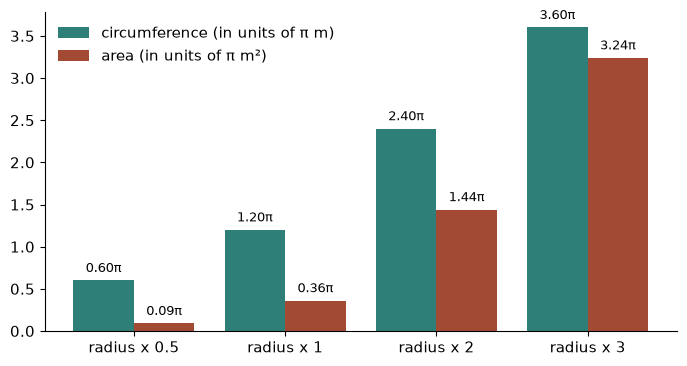

In [7]:
ks = [0.5, 1, 2, 3]
circ = [1.2 * k for k in ks]       # in multiples of pi
area = [0.36 * k * k for k in ks]
x = np.arange(len(ks))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - 0.2, circ, 0.4, color=TEAL, label="circumference (in units of \u03c0 m)")
ax.bar(x + 0.2, area, 0.4, color=TERRA, label="area (in units of \u03c0 m\u00b2)")
for i in x:
    ax.text(i - 0.2, circ[i] + 0.1, f"{circ[i]:.2f}\u03c0", ha="center", fontsize=9)
    ax.text(i + 0.2, area[i] + 0.1, f"{area[i]:.2f}\u03c0", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([f"radius x {k}" for k in ks])
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What this shows:** doubling the radius doubles the circumference (one factor of 2) but quadruples the area (two factors of 2, since $r$ is multiplied by itself). That gives you a quick magnitude check: if a radius doubles and a reported area only doubles, something went wrong.

**Where it stops working:** this is a scaled ideal circle. Circumference and area are different kinds of quantity (meters versus square meters), so they cannot be compared directly, only their growth factors can.

## 4. Measure an angle by its arc

**Question:** how long is the arc reached by a central angle of 120 degrees?

**The equations from the chapter:**

$$s = r\theta \qquad\qquad \theta = \frac{s}{r}$$

**What the symbols mean:** $\theta$ is the central angle in radians. $r$ is the radius. $s$ is the length of the arc the angle reaches. A full turn is $2\pi$ radians, which is 360 degrees.

**Predict first:** on a circle of radius 3, will 120 degrees reach a third of the way around? How long is that?

In [8]:
def pif(frac):
    """A multiple of pi written as the chapter writes it: pi/2, 2pi/3, 3pi/2."""
    frac = Fraction(frac)
    top = "\u03c0" if frac.numerator == 1 else f"{frac.numerator}\u03c0"
    return top if frac.denominator == 1 else f"{top}/{frac.denominator}"

def arc(deg, r):
    turn = Fraction(deg, 360)
    theta = turn * 2
    s = r * theta
    circ = 2 * r
    turn_txt = str(turn.numerator) if turn.denominator == 1 else f"{turn.numerator}/{turn.denominator}"
    say("Fraction of a turn", f"{deg}/360 = {turn_txt}")
    say("\u03b8 in radians", f"{turn_txt} x 2\u03c0 = {pif(theta)}")
    say("Arc length s = r\u03b8", f"{r} x {pif(theta)} = {pif(s)} \u2248 {math.pi * float(s):.2f}")
    say("Full circumference", f"2\u03c0 x {r} = {pif(circ)}")
    return theta, s

theta, s = arc(120, 3)
print()
print("Other menu values, radius 3:")
for deg in [90, 180, 360]:
    print(f"central angle {deg} degrees:")
    arc(deg, 3)

Fraction of a turn: 120/360 = 1/3
θ in radians: 1/3 x 2π = 2π/3
Arc length s = rθ: 3 x 2π/3 = 2π ≈ 6.28
Full circumference: 2π x 3 = 6π

Other menu values, radius 3:
central angle 90 degrees:
Fraction of a turn: 90/360 = 1/4
θ in radians: 1/4 x 2π = π/2
Arc length s = rθ: 3 x π/2 = 3π/2 ≈ 4.71
Full circumference: 2π x 3 = 6π
central angle 180 degrees:
Fraction of a turn: 180/360 = 1/2
θ in radians: 1/2 x 2π = π
Arc length s = rθ: 3 x π = 3π ≈ 9.42
Full circumference: 2π x 3 = 6π
central angle 360 degrees:
Fraction of a turn: 360/360 = 1
θ in radians: 1 x 2π = 2π
Arc length s = rθ: 3 x 2π = 6π ≈ 18.85
Full circumference: 2π x 3 = 6π


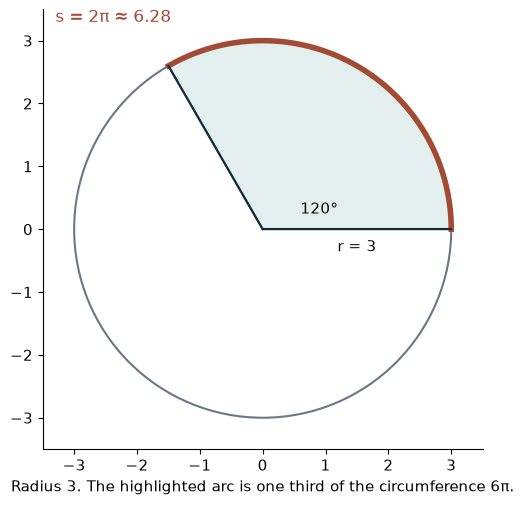

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
r = 3
ax.add_patch(Circle((0, 0), r, fill=False, edgecolor=GREY, linewidth=1.5))
ax.add_patch(Wedge((0, 0), r, 0, 120, facecolor="#e3efee", edgecolor=TEAL, linewidth=1.5))
t = np.linspace(0, np.radians(120), 100)
ax.plot(r * np.cos(t), r * np.sin(t), color=TERRA, linewidth=4)
ax.plot([0, r], [0, 0], color=INK); ax.plot([0, r * np.cos(t[-1])], [0, r * np.sin(t[-1])], color=INK)
ax.text(0.6, 0.25, "120\u00b0", fontsize=11)
ax.text(1.5, -0.35, "r = 3", ha="center")
ax.text(-3.3, 3.3, f"s = 2\u03c0 \u2248 {2*math.pi:.2f}", color=TERRA, fontsize=12)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal")
ax.set_xlabel("Radius 3. The highlighted arc is one third of the circumference 6\u03c0.")
plt.tight_layout(); plt.show()

**What this shows:** an angle in radians is the arc it reaches measured in radii. 120 degrees is a third of a turn, so $\theta = 2\pi/3$, and on radius 3 the arc is $3 \times 2\pi/3 = 2\pi$. The check by fraction of the circumference agrees: $\tfrac{1}{3} \times 6\pi = 2\pi$.

**Where it stops working:** $s = r\theta$ needs $\theta$ in radians, not degrees. And it describes an ideal circle with a declared radius.

## Practice

**1.** A circle has diameter 10 units. What is its exact circumference, and what is $C/d$?

<details><summary>Show answer</summary>

$C = \pi d = \pi \times 10 = 10\pi$, which is about $31.42$ units ($3.14159 \times 10 = 31.4159$).
$C / d = 10\pi / 10 = \pi$.

</details>

**2.** A circle has circumference $20\pi$ centimeters. What are its radius and its area?

<details><summary>Show answer</summary>

$2\pi r = 20\pi$, so $r = 20\pi / 2\pi = 10$ cm.
Area: $\pi r^2 = \pi \times 10^2 = 100\pi$ square centimeters.
Check: $2\pi \times 10 = 20\pi$.

</details>

**3.** On a circle of radius 6, how long is the arc for a central angle of 60 degrees? Also: if the radius is multiplied by 5, by what factors do circumference and area change?

<details><summary>Show answer</summary>

$60/360 = 1/6$ of a turn, so $\theta = (1/6) \times 2\pi = \pi/3$.
Then $s = r\theta = 6 \times \pi/3 = 2\pi$. Check: $(1/6) \times 2\pi \times 6 = (1/6) \times 12\pi = 2\pi$.

Radius times 5: circumference changes by a factor of 5, and area by $5 \times 5 = 25$.

</details>